# Kasus 3: Sisa umur pakai motor induksi (RUL)

Kelompok 3:

*   Nafila Ajmal (2400721)
*   Nur Adila Putri (2402916)





In [5]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")          # kalau dijalankan di VS Code dari folder notebooks/
PATH = "data/raw.csv"
if not os.path.exists(PATH):
    os.makedirs("data", exist_ok=True)
    try:
        from google.colab import files           # khusus Colab: pilih raw.csv
        up = files.upload(); open(PATH, "wb").write(list(up.values())[0])
    except ImportError:
        raise FileNotFoundError("Taruh raw.csv di folder data/")
os.makedirs("artifacts", exist_ok=True)
raw = pd.read_csv(PATH)
print(raw.shape); raw.head()

(79652, 11)


,motor_id,tipe_motor,lokasi,hari_operasi,beban_pct,arus_A,tegangan_V,suhu_belitan_C,getaran_rms_mm_s,kecepatan_rpm,rul_hari
0,M-001,5.5kW,Plant Purwakarta,0,95.4,10.47,376.5,337.2,2.08,1472.0,251
1,M-001,5.5kW,Plant Purwakarta,1,82.1,8.81,382.0,332.8,2.14,1476.0,250
2,M-001,5.5kW,Plant Purwakarta,2,82.3,8.74,383.8,328.0,2.00,1474.0,249
3,M-001,5.5kW,Plant Purwakarta,3,80.7,8.42,377.0,333.3,2.03,1476.0,248
4,M-001,5.5kW,Plant Purwakarta,4,89.3,9.46,384.5,333.2,2.06,1477.0,247


## 1. Kenali data

In [6]:
print(raw.isna().sum())
print("baris duplikat (motor_id + hari_operasi):", raw.duplicated(["motor_id","hari_operasi"]).sum())
print("jumlah motor_id unik (mentah):", raw.motor_id.nunique(), "-> seharusnya 300")
print(raw.tipe_motor.value_counts())
print("suhu > 200 per lokasi:"); print((raw.suhu_belitan_C > 200).groupby(raw.lokasi).mean())
print("getaran <= 0:", (raw.getaran_rms_mm_s <= 0).sum(), "| beban > 100:", (raw.beban_pct > 100).sum())
raw.describe().T

motor_id               0
tipe_motor             0
lokasi                 0
hari_operasi           0
beban_pct              0
arus_A              1602
tegangan_V             0
suhu_belitan_C       794
getaran_rms_mm_s       0
kecepatan_rpm          0
rul_hari               0
dtype: int64
baris duplikat (motor_id + hari_operasi): 493
jumlah motor_id unik (mentah): 1147 -> seharusnya 300
tipe_motor
11kW      35041
5.5kW     29211
22kW      13812
22KW        549
11 kW       533
5,5 kW      506
Name: count, dtype: int64
suhu > 200 per lokasi:
lokasi
Plant Cikarang      0.000000
Plant Karawang      0.000000
Plant Purwakarta    0.989541
Name: suhu_belitan_C, dtype: float64
getaran <= 0: 241 | beban > 100: 797


,count,mean,std,min,25%,50%,75%,max
hari_operasi,79652.0,149.771481,102.894696,0.00,67.00,135.00,216.00,543.00
beban_pct,79652.0,74.690018,12.435699,38.90,64.90,74.40,84.40,110.00
arus_A,78050.0,15.954332,8.746818,4.13,8.78,14.22,19.31,47.24
tegangan_V,79652.0,379.997084,3.996098,363.40,377.30,380.00,382.70,396.80
suhu_belitan_C,78858.0,153.037131,127.737506,39.60,61.40,70.60,330.80,372.00
getaran_rms_mm_s,79652.0,2.998297,1.428476,-1.00,2.06,2.35,3.48,8.01
kecepatan_rpm,79652.0,1470.669035,5.853770,1451.00,1467.00,1472.00,1475.00,1485.00
rul_hari,79652.0,149.743095,102.930091,0.00,66.00,135.00,217.00,543.00


Temuan: ID motor dan tipe motor ditulis tidak seragam; suhu Plant Purwakarta berupa Kelvin; getaran `-1` adalah kode sensor error; ada nilai kosong dan baris duplikat.

## 2. Pembersihan

In [7]:
masalah = []
d = raw.copy()

# 1) ID motor -> M-###
d["motor_id"] = "M-" + d.motor_id.str.replace(r"\D", "", regex=True).astype(int).astype(str).str.zfill(3)
masalah.append(("motor_id tidak seragam", int((raw.motor_id != d.motor_id).sum()), "dinormalkan jadi M-###"))

# 2) tipe_motor -> 5.5kW / 11kW / 22kW
t = d.tipe_motor.str.upper().str.replace(" ", "").str.replace(",", ".")
t = t.str.replace("KW", "kW")
masalah.append(("tipe_motor tidak seragam", int((d.tipe_motor != t).sum()), "dinormalkan"))
d["tipe_motor"] = t

# 3) suhu Kelvin -> Celsius (Plant Purwakarta)
k = d.suhu_belitan_C > 200
d.loc[k, "suhu_belitan_C"] -= 273.15
masalah.append(("suhu dalam Kelvin", int(k.sum()), "dikurangi 273,15"))

# 4) getaran -1 = sensor error -> NaN
e = d.getaran_rms_mm_s <= 0
d.loc[e, "getaran_rms_mm_s"] = np.nan
masalah.append(("getaran = -1 (sensor error)", int(e.sum()), "diubah NaN, diimputasi di pipeline"))

# 5) duplikat
n_dup = int(d.duplicated(["motor_id","hari_operasi"]).sum())
d = d.drop_duplicates(["motor_id","hari_operasi"]).sort_values(["motor_id","hari_operasi"]).reset_index(drop=True)
masalah.append(("baris duplikat", n_dup, "drop_duplicates"))

# 6) nilai kosong: dibiarkan NaN, diimputasi di pipeline (fit hanya di train)
masalah.append(("arus_A kosong", int(d.arus_A.isna().sum()), "imputasi median di pipeline"))
masalah.append(("suhu_belitan_C kosong", int(d.suhu_belitan_C.isna().sum()), "imputasi median di pipeline"))
masalah.append(("beban_pct > 100", int((d.beban_pct > 100).sum()), "dipertahankan (overload wajar)"))

print("motor unik:", d.motor_id.nunique(), "| baris:", len(d))
pd.DataFrame(masalah, columns=["masalah", "jumlah_baris", "penanganan"])

motor unik: 300 | baris: 79159


,masalah,jumlah_baris,penanganan
0,motor_id tidak seragam,3185,dinormalkan jadi M-###
1,tipe_motor tidak seragam,1588,dinormalkan
2,suhu dalam Kelvin,25355,"dikurangi 273,15"
3,getaran = -1 (sensor error),241,"diubah NaN, diimputasi di pipeline"
4,baris duplikat,493,drop_duplicates
5,arus_A kosong,1588,imputasi median di pipeline
6,suhu_belitan_C kosong,787,imputasi median di pipeline
7,beban_pct > 100,788,dipertahankan (overload wajar)


In [8]:
d.to_csv("data/clean.csv", index=False)
d.describe().T

,count,mean,std,min,25%,50%,75%,max
hari_operasi,79159.0,149.810091,102.899235,0.00,67.00,135.00,217.00,543.00
beban_pct,79159.0,74.690806,12.436756,38.90,64.90,74.40,84.40,110.00
arus_A,77571.0,15.952904,8.747596,4.13,8.78,14.22,19.31,47.24
tegangan_V,79159.0,379.998092,3.996418,363.40,377.30,380.00,382.70,396.80
suhu_belitan_C,78372.0,65.214260,8.897089,39.60,58.65,64.05,70.90,98.85
getaran_rms_mm_s,78920.0,3.010493,1.413480,1.53,2.06,2.35,3.49,8.01
kecepatan_rpm,79159.0,1470.667543,5.854148,1451.00,1467.00,1472.00,1475.00,1485.00
rul_hari,79159.0,149.711126,102.884276,0.00,66.00,135.00,216.00,543.00


## 3. EDA

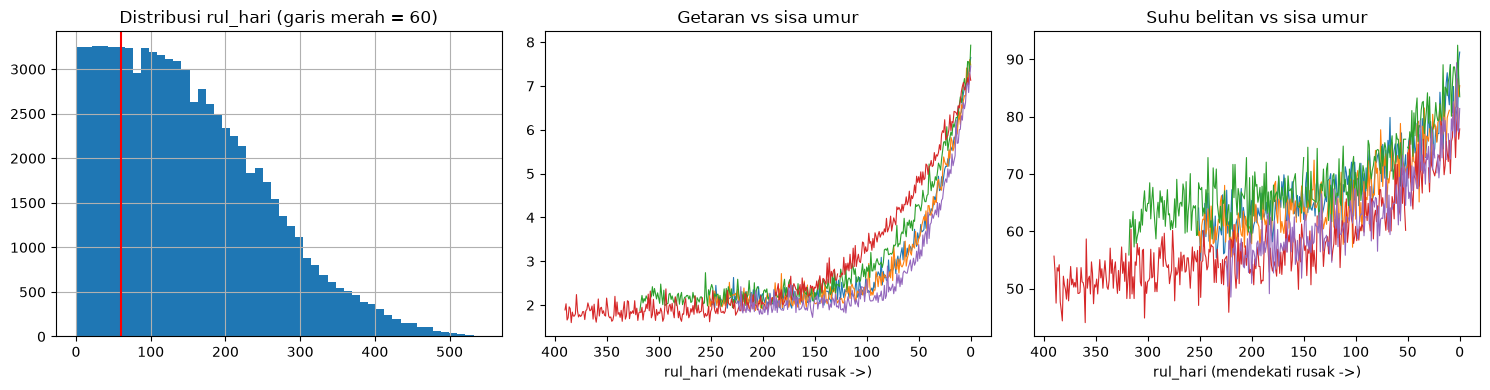

porsi baris rul<=60: 0.228


getaran_rms_mm_s   -0.694584
suhu_belitan_C     -0.683160
hari_operasi       -0.565385
arus_A             -0.097300
beban_pct          -0.065620
tegangan_V         -0.009158
kecepatan_rpm       0.728035
rul_hari            1.000000
Name: rul_hari, dtype: float64

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
d.rul_hari.hist(bins=50, ax=ax[0]); ax[0].axvline(60, color="r"); ax[0].set_title("Distribusi rul_hari (garis merah = 60)")
for m in d.motor_id.unique()[:5]:
    s = d[d.motor_id == m]
    ax[1].plot(s.rul_hari, s.getaran_rms_mm_s, lw=.8); ax[2].plot(s.rul_hari, s.suhu_belitan_C, lw=.8)
for a, t in zip(ax[1:], ["Getaran vs sisa umur", "Suhu belitan vs sisa umur"]):
    a.invert_xaxis(); a.set_xlabel("rul_hari (mendekati rusak ->)"); a.set_title(t)
plt.tight_layout(); plt.show()
print("porsi baris rul<=60:", round((d.rul_hari <= 60).mean(), 3))
d.drop(columns=["motor_id","tipe_motor","lokasi"]).corr()["rul_hari"].sort_values()

## 4. Pembagian data per `motor_id` (70/15/15)
Motor di *validation*/*test* tidak boleh muncul di *train*: kalau satu motor ada di dua bagian, model bisa menghafal pola motor itu dan MAE terlihat bagus padahal tidak akan berlaku untuk motor baru. Baris satu motor juga saling mirip dari hari ke hari.

In [10]:
SEED = 42
g1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
tr_i, rest_i = next(g1.split(d, groups=d.motor_id))
rest = d.iloc[rest_i]
g2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
va_i, te_i = next(g2.split(rest, groups=rest.motor_id))
train, val, test = d.iloc[tr_i], rest.iloc[va_i], rest.iloc[te_i]

assert not set(train.motor_id) & set(val.motor_id) and not set(train.motor_id) & set(test.motor_id) and not set(val.motor_id) & set(test.motor_id)
print({k: (v.motor_id.nunique(), len(v)) for k, v in dict(train=train, val=val, test=test).items()})

os.makedirs("artifacts", exist_ok=True)
json.dump({"train": sorted(train.motor_id.unique()), "val": sorted(val.motor_id.unique()), "test": sorted(test.motor_id.unique())},
          open("artifacts/split_motor.json", "w"))

{'train': (210, 54262), 'val': (45, 12293), 'test': (45, 12604)}


## 5. Baseline: regresi linear (fitur sensor asli + tipe motor)
`hari_operasi` tidak dipakai karena bukan masukan aplikasi.

In [11]:
SENSOR = ["beban_pct","arus_A","tegangan_V","suhu_belitan_C","getaran_rms_mm_s","kecepatan_rpm"]
def siapkan(df):
    X = df[SENSOR].copy()
    for t in ["5.5kW","11kW","22kW"]:
        X["tipe_" + t] = (df.tipe_motor == t).astype(int)
    return X

def mae_dua(y, p):
    m = y <= 60
    return round(mean_absolute_error(y, p), 2), round(mean_absolute_error(y[m], p[m]), 2)

base = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
base.fit(siapkan(train), train.rul_hari)
for nama, df in [("train", train), ("validation", val)]:
    semua, dekat = mae_dua(df.rul_hari.values, base.predict(siapkan(df)))
    print(f"Baseline linear | {nama:10s} | MAE semua baris = {semua} hari | MAE rul<=60 = {dekat} hari")

Baseline linear | train      | MAE semua baris = 46.3 hari | MAE rul<=60 = 29.4 hari
Baseline linear | validation | MAE semua baris = 52.45 hari | MAE rul<=60 = 31.65 hari


# Fitur, model final, dan artifact


## 1. Fitur

In [12]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")          # selalu bekerja dari root repo
os.makedirs("src", exist_ok=True); os.makedirs("artifacts", exist_ok=True)

In [13]:
%%writefile src/features.py
"""Fitur turunan RUL motor. Dipakai saat pelatihan DAN saat prediksi (app)."""
import numpy as np
import pandas as pd

SENSOR = ["beban_pct", "arus_A", "tegangan_V", "suhu_belitan_C", "getaran_rms_mm_s", "kecepatan_rpm"]
TIPE = ["5.5kW", "11kW", "22kW"]
ARUS_NOMINAL = {"5.5kW": 8.1, "11kW": 16.2, "22kW": 31.5}   # median arus per tipe pada data bersih
RPM_SINKRON = 1500                                          # motor 4 kutub, 50 Hz


def buat_fitur(df: pd.DataFrame) -> pd.DataFrame:
    """df berisi kolom tipe_motor + SENSOR. Mengembalikan tabel fitur numerik (NaN dibiarkan)."""
    X = df[SENSOR].astype(float).copy()
    for t in TIPE:
        X["tipe_" + t] = (df["tipe_motor"] == t).astype(int)
    nominal = df["tipe_motor"].map(ARUS_NOMINAL).astype(float)
    X["arus_rel"] = X["arus_A"] / nominal                         # arus dibanding arus normal tipenya
    X["arus_per_beban"] = X["arus_A"] / X["beban_pct"]            # arus naik tanpa beban naik = tanda masalah
    X["slip_rpm"] = RPM_SINKRON - X["kecepatan_rpm"]              # makin lambat = makin berat
    X["getaran_x_suhu"] = X["getaran_rms_mm_s"] * X["suhu_belitan_C"]
    return X

Overwriting src/features.py


In [14]:
import os, sys, json, platform, numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, sklearn
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")   # selalu bekerja dari root repo
sys.path.insert(0, ".")
os.makedirs("src", exist_ok=True); open("src/__init__.py", "a").close()
from src.features import buat_fitur, SENSOR
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error

d = pd.read_csv("data/clean.csv")
split = json.load(open("artifacts/split_motor.json"))
train, val, test = [d[d.motor_id.isin(split[k])] for k in ("train", "val", "test")]
FITUR_INPUT = ["tipe_motor"] + SENSOR

def mae_dua(y, p):
    y, p = np.asarray(y), np.asarray(p); m = y <= 60
    return round(mean_absolute_error(y, p), 2), round(mean_absolute_error(y[m], p[m]), 2)
print(len(train), len(val), len(test))

54262 12293 12604


## 2. Baseline dan model kandidat (diukur di *validation*)
Dua angka per model: MAE semua baris, dan MAE `rul_hari ≤ 60` (metrik utama).

In [15]:
def model_gbm(**kw):
    p = dict(max_iter=500, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=5, min_samples_leaf=50, random_state=0)
    p.update(kw)
    # target di-log agar kesalahan di sisa umur kecil lebih diperhatikan; NaN ditangani langsung oleh model
    return TransformedTargetRegressor(HistGradientBoostingRegressor(**p), func=np.log1p, inverse_func=np.expm1)

SENS_TIPE = SENSOR + ["tipe_5.5kW", "tipe_11kW", "tipe_22kW"]
Xtr, Xva = buat_fitur(train), buat_fitur(val)
kandidat = {
    "Baseline: regresi linear (sensor asli)": (make_pipeline(SimpleImputer(strategy="median"), LinearRegression()), SENS_TIPE),
    "Gradient boosting, sensor asli": (model_gbm(), SENS_TIPE),
    "Gradient boosting + fitur turunan": (model_gbm(), list(Xtr.columns)),
}
hasil = []
for nama, (m, cols) in kandidat.items():
    m.fit(Xtr[cols], train.rul_hari)
    a, b = mae_dua(val.rul_hari, m.predict(Xva[cols]))
    hasil.append((nama, a, b))
pd.DataFrame(hasil, columns=["model", "MAE semua baris", "MAE rul<=60 (utama)"])

,model,MAE semua baris,MAE rul<=60 (utama)
0,Baseline: regresi linear (sensor asli),52.45,31.65
1,"Gradient boosting, sensor asli",46.65,12.07
2,Gradient boosting + fitur turunan,46.47,12.08


## 3. Tuning kecil (hanya di *validation*)

In [16]:
grid = [dict(max_leaf_nodes=l, l2_regularization=r) for l in (15, 31) for r in (0, 5)]
rows = []
for g in grid:
    m = model_gbm(**g).fit(Xtr, train.rul_hari)
    rows.append({**g, **dict(zip(["MAE_semua", "MAE_rul<=60"], mae_dua(val.rul_hari, m.predict(Xva))))})
pd.DataFrame(rows)

,max_leaf_nodes,l2_regularization,MAE_semua,MAE_rul<=60
0,15,0,46.46,12.08
1,15,5,46.47,12.08
2,31,0,46.52,12.08
3,31,5,46.52,12.07


Selisih antar konfigurasi sangat kecil, jadi kita pakai yang sederhana (`max_leaf_nodes=15`, `l2=5`) dan tidak tuning berlebihan.

## 4. Di mana model kuat dan lemah?

          count   mean
pita_rul              
0-14        662   3.71
15-28       619   8.72
29-60      1410  17.48
61-120     2612  35.71
>120       6990  63.73


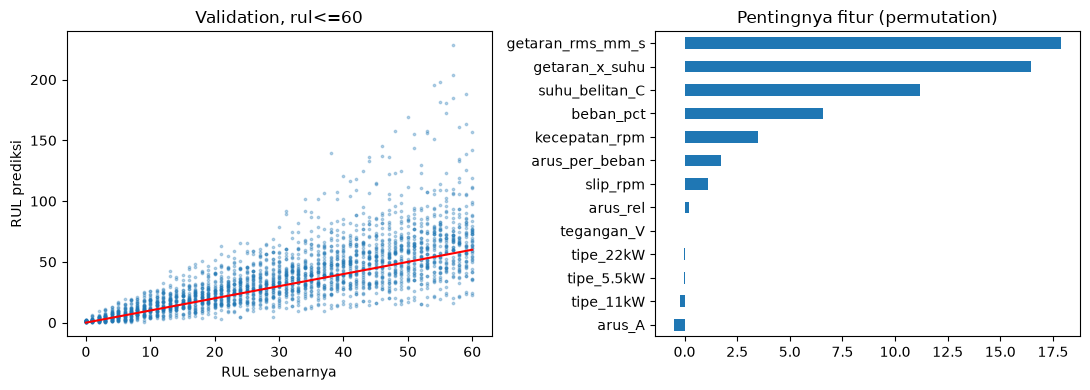

In [17]:
final_val = model_gbm().fit(Xtr, train.rul_hari)
p = final_val.predict(Xva); y = val.rul_hari.values
pita = pd.cut(y, [-1, 14, 28, 60, 120, 600], labels=["0-14", "15-28", "29-60", "61-120", ">120"])
print(pd.DataFrame({"pita_rul": pita, "galat": np.abs(p - y)}).groupby("pita_rul", observed=True).galat.agg(["count", "mean"]).round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
mk = y <= 60
ax[0].scatter(y[mk], p[mk], s=3, alpha=.3); ax[0].plot([0, 60], [0, 60], "r"); ax[0].set_xlabel("RUL sebenarnya"); ax[0].set_ylabel("RUL prediksi"); ax[0].set_title("Validation, rul<=60")
imp = pd.Series(dict(zip(Xtr.columns, np.zeros(len(Xtr.columns)))))
from sklearn.inspection import permutation_importance
sub = val.sample(4000, random_state=0); r = permutation_importance(final_val, buat_fitur(sub), sub.rul_hari, n_repeats=3, random_state=0, scoring="neg_mean_absolute_error")
pd.Series(r.importances_mean, index=Xtr.columns).sort_values().plot.barh(ax=ax[1]); ax[1].set_title("Pentingnya fitur (permutation)")
plt.tight_layout(); plt.show()

## 5. Status untuk perencana
Pengiriman motor pengganti 2–4 minggu (maks. 28 hari). Aturan: prediksi ≤ 14 hari → **segera ganti**; ≤ 35 hari (28 hari + cadangan 7 hari) → **pesan pengganti sekarang**; selain itu → **aman**.

In [18]:
SEGERA, PESAN = 14, 35
def status(rul): return np.where(rul <= SEGERA, "segera ganti", np.where(rul <= PESAN, "pesan pengganti sekarang", "aman"))
st = status(p)
butuh = y <= 28   # motor yang benar-benar perlu pesan penggantinya sekarang
print("motor yg rul sebenarnya <=28 hari ditandai 'aman' (terlewat):", round((st[butuh] == "aman").mean() * 100, 1), "%")
print("motor yg rul sebenarnya >60 hari tetapi bukan 'aman' (alarm palsu):", round((st[y > 60] != "aman").mean() * 100, 1), "%")
pd.crosstab(pd.cut(y, [-1, 14, 28, 60, 600], labels=["0-14", "15-28", "29-60", ">60"]), st)

motor yg rul sebenarnya <=28 hari ditandai 'aman' (terlewat): 9.8 %
motor yg rul sebenarnya >60 hari tetapi bukan 'aman' (alarm palsu): 0.7 %


col_0,aman,pesan pengganti sekarang,segera ganti
row_0,,,
0-14,4,144,514
15-28,121,425,73
29-60,1087,305,18
>60,9535,67,0


## 6. Latih ulang final: train + validation
Setelah memilih model di *validation*, model dilatih ulang pada gabungan train + validation (lebih banyak motor).

In [19]:
trval = pd.concat([train, val])
final = Pipeline([("fitur", FunctionTransformer(buat_fitur)), ("model", model_gbm())]).fit(trval[FITUR_INPUT], trval.rul_hari)
base = Pipeline([("fitur", FunctionTransformer(lambda df: buat_fitur(df)[SENS_TIPE])),
                 ("imp", SimpleImputer(strategy="median")), ("lin", LinearRegression())]).fit(trval[FITUR_INPUT], trval.rul_hari)
print("model final siap dilatih ulang")

model final siap dilatih ulang


## 7. Buka data *test* — SEKALI SAJA

In [20]:
# Jalankan sel ini sekali di akhir. Jangan mengubah model setelah melihat angkanya.
Xte = test[FITUR_INPUT]
ptest = np.clip(final.predict(Xte), 0, None)
test_final = mae_dua(test.rul_hari, ptest)
test_base = mae_dua(test.rul_hari, base.predict(Xte))
val_final = mae_dua(val.rul_hari, final_val.predict(Xva))
val_base = hasil[0][1:]
print(pd.DataFrame({"validation (MAE semua, MAE<=60)": [val_base, val_final], "test (MAE semua, MAE<=60)": [test_base, test_final]},
                   index=["Baseline linear", "Gradient boosting + fitur"]))

                          validation (MAE semua, MAE<=60)  \
Baseline linear                            (52.45, 31.65)   
Gradient boosting + fitur                  (46.47, 12.08)   

                          test (MAE semua, MAE<=60)  
Baseline linear                      (55.03, 30.38)  
Gradient boosting + fitur            (51.88, 11.62)  


## 8. Simpan artifact

In [21]:
os.makedirs("artifacts", exist_ok=True)
joblib.dump(final, "artifacts/model.joblib")
meta = {
    "versi_model": "1.0.0",
    "dibuat": str(pd.Timestamp.today().date()),
    "fitur_input": FITUR_INPUT,
    "target": "rul_hari",
    "tipe_motor_valid": ["5.5kW", "11kW", "22kW"],
    "threshold": {"segera_ganti_hari": SEGERA, "pesan_pengganti_hari": PESAN},   # aturan status (dibaca oleh aplikasi)
    "metrik_validasi": {"baseline_mae_semua": val_base[0], "baseline_mae_rul60": val_base[1],
                        "final_mae_semua": val_final[0], "final_mae_rul60": val_final[1]},
    "metrik_test": {"baseline_mae_semua": test_base[0], "baseline_mae_rul60": test_base[1],
                    "final_mae_semua": test_final[0], "final_mae_rul60": test_final[1]},
    "versi_library": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                      "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__},
}
json.dump(meta, open("artifacts/metadata.json", "w"), indent=2)
# uji muat ulang
m2 = joblib.load("artifacts/model.joblib")
print(m2.predict(pd.DataFrame([{"tipe_motor": "11kW", "beban_pct": 80, "arus_A": 16, "tegangan_V": 380, "suhu_belitan_C": 70, "getaran_rms_mm_s": 3.5, "kecepatan_rpm": 1470}])))
print(json.dumps(meta, indent=1))

[84.69966031]
{
 "versi_model": "1.0.0",
 "dibuat": "2026-11-18",
 "fitur_input": [
  "tipe_motor",
  "beban_pct",
  "arus_A",
  "tegangan_V",
  "suhu_belitan_C",
  "getaran_rms_mm_s",
  "kecepatan_rpm"
 ],
 "target": "rul_hari",
 "tipe_motor_valid": [
  "5.5kW",
  "11kW",
  "22kW"
 ],
 "threshold": {
  "segera_ganti_hari": 14,
  "pesan_pengganti_hari": 35
 },
 "metrik_validasi": {
  "baseline_mae_semua": 52.45,
  "baseline_mae_rul60": 31.65,
  "final_mae_semua": 46.47,
  "final_mae_rul60": 12.08
 },
 "metrik_test": {
  "baseline_mae_semua": 55.03,
  "baseline_mae_rul60": 30.38,
  "final_mae_semua": 51.88,
  "final_mae_rul60": 11.62
 },
 "versi_library": {
  "python": "3.12.10",
  "sklearn": "1.6.1",
  "pandas": "2.2.3",
  "numpy": "2.4.6",
  "joblib": "1.6.0"
 }
}


## 9. Catat versi library & kemas hasil
`requirements_model.txt` berisi versi library saat model dilatih. Pakai versi yang sama di VS Code / Streamlit supaya `model.joblib` terbaca.

In [22]:
import shutil, importlib.metadata as im
pins = [f"{p}=={im.version(p)}" for p in ["scikit-learn", "pandas", "numpy", "joblib"]]
open("artifacts/requirements_model.txt", "w").write("\n".join(pins) + "\n")
print("\n".join(pins))

import zipfile
with zipfile.ZipFile("hasil_kasus03.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in ["data/clean.csv", "artifacts/model.joblib", "artifacts/metadata.json",
              "artifacts/split_motor.json", "artifacts/requirements_model.txt", "src/features.py", "src/__init__.py"]:
        z.write(f)
try:
    from google.colab import files
    files.download("hasil_kasus03.zip")
except ImportError:
    print("Bukan Colab: hasil_kasus03.zip ada di folder kerja.")

scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0
Bukan Colab: hasil_kasus03.zip ada di folder kerja.
